# LDA Topic Modelling by Primary Category

This notebook performs topic modelling using Latent Dirichlet Allocation (LDA) on arXiv abstracts.

## Objectives
- Load the cleaned arXiv dataset
- Perform basic exploratory data analysis (EDA)
- Filter data for one selected primary category
- Apply shared preprocessing from `lda_nmf_preprocessing.py`
- Explore unigrams, bigrams, and trigrams
- Train LDA models with different topic numbers
- Evaluate topic quality using coherence score
- Inspect the learned topics

In [1]:
# Uncomment and run if needed

# !pip install pandas numpy matplotlib
# !pip install nltk gensim scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import gensim
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
from gensim.models.phrases import Phrases, Phraser
from gensim.models.ldamodel import LdaModel

## Load Dataset

We first load the cleaned arXiv metadata file and inspect its structure.

In [3]:
# load dataset
df = pd.read_csv("../data/arxiv_cleaned_metadata.csv")

print(df.shape)
df.head()

(19973, 17)


,id,title,abstract,published,updated,authors,primary_category,all_categories,queried_category,broad_subject,title_clean,abstract_clean,text,abstract_word_count,title_word_count,base_id,version
0,http://arxiv.org/abs/0704.1169v1,Holographic bound and protein linguistics,The holographic bound in physics constrains th...,2007-04-10T12:04:28Z,2007-04-10T12:04:28Z,"Dirson Jian Li, Shengli Zhang",q-bio.GN,"q-bio.GN, hep-th, q-bio.QM",q-bio.GN,biology,holographic bound and protein linguistics,the holographic bound in physics constrains th...,holographic bound and protein linguistics the ...,66,5,704.1169,1.0
1,http://arxiv.org/abs/0704.2191v2,Mismatch Repair Error Implies Chargaff's Secon...,Chargaff's second parity rule holds empiricall...,2007-04-17T16:15:37Z,2007-09-20T15:46:34Z,Bo Deng,q-bio.GN,q-bio.GN,q-bio.GN,biology,mismatch repair error implies chargaff's secon...,chargaff's second parity rule holds empiricall...,mismatch repair error implies chargaff's secon...,155,8,704.2191,2.0
2,http://arxiv.org/abs/0704.3826v2,Non-coding DNA programs express adaptation and...,Significant fraction (98.5% in humans) of most...,2007-04-29T05:32:50Z,2007-08-02T16:23:54Z,Mark Ya. Azbel,q-bio.GN,"q-bio.GN, cond-mat.other, nlin.AO, q-bio.OT, q...",q-bio.GN,biology,non-coding dna programs express adaptation and...,significant fraction (98.5% in humans) of most...,non-coding dna programs express adaptation and...,161,9,704.3826,2.0
3,http://arxiv.org/abs/0705.1656v1,Chromatin Folding in Relation to Human Genome ...,Three-dimensional (3D) chromatin structure is ...,2007-05-11T14:12:05Z,2007-05-11T14:12:05Z,"Julio Mateos-Langerak, Osdilly Giromus, Wim de...",q-bio.GN,q-bio.GN,q-bio.GN,biology,chromatin folding in relation to human genome ...,three-dimensional (3d) chromatin structure is ...,chromatin folding in relation to human genome ...,226,8,705.1656,1.0
4,http://arxiv.org/abs/0705.2143v1,Inverted and mirror repeats in model nucleotid...,We analytically and numerically study the prob...,2007-05-15T13:37:17Z,2007-05-15T13:37:17Z,"Fabrizio Lillo, Marco Spanó",q-bio.GN,"q-bio.GN, q-bio.QM",q-bio.GN,biology,inverted and mirror repeats in model nucleotid...,we analytically and numerically study the prob...,inverted and mirror repeats in model nucleotid...,79,8,705.2143,1.0


In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (19973, 17)

Columns:
['id', 'title', 'abstract', 'published', 'updated', 'authors', 'primary_category', 'all_categories', 'queried_category', 'broad_subject', 'title_clean', 'abstract_clean', 'text', 'abstract_word_count', 'title_word_count', 'base_id', 'version']


## Basic EDA

We check for missing values, category distribution, and abstract length to understand the dataset before topic modelling.

count    19973.000000
mean       165.876834
std         50.715755
min         20.000000
25%        130.000000
50%        162.000000
75%        200.000000
max        539.000000
Name: abstract_word_count, dtype: float64


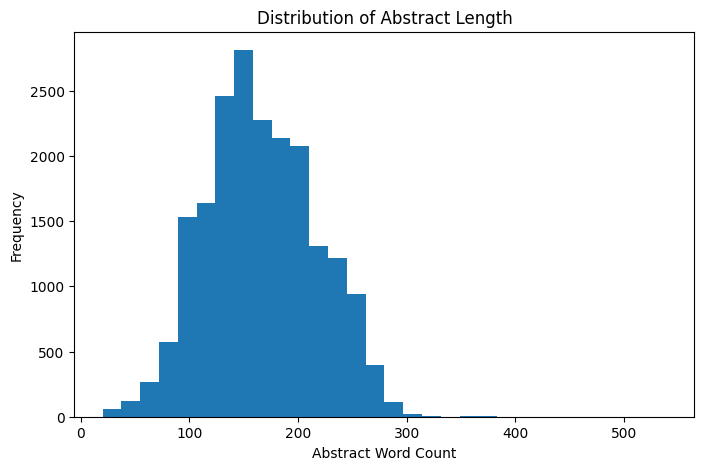

In [5]:
df["abstract_word_count"] = df["abstract"].fillna("").apply(lambda x: len(str(x).split()))

print(df["abstract_word_count"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["abstract_word_count"], bins=30)
plt.xlabel("Abstract Word Count")
plt.ylabel("Frequency")
plt.title("Distribution of Abstract Length")
plt.show()

## Apply Shared Preprocessing to All Abstracts

The same base preprocessing is applied to all documents to ensure consistency across later topic models. This shared preprocessing includes text cleaning, tokenization, stopword removal, and lemmatization.

At this stage, only general preprocessing is applied. Phrase modelling such as bigrams and trigrams will be performed later within each primary category, since meaningful phrases may differ across categories.

In [ ]:
import lda_nmf_preprocessing

df["tokens_clean"] = df["text"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(x)
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [7]:
df[["text", "tokens_clean"]].head(20)

,text,tokens_clean
0,holographic bound and protein linguistics the ...,"[holographic, bound, protein, linguistics, hol..."
1,mismatch repair error implies chargaff's secon...,"[mismatch, repair, error, implies, chargaff, s..."
2,non-coding dna programs express adaptation and...,"[non-coding, dna, program, express, adaptation..."
3,chromatin folding in relation to human genome ...,"[chromatin, folding, relation, human, genome, ..."
4,inverted and mirror repeats in model nucleotid...,"[inverted, mirror, repeat, model, nucleotide, ..."
5,towards understanding the origin of genetic la...,"[towards, understanding, origin, genetic, lang..."
6,reciprocal best hits are not a logically suffi...,"[reciprocal, best, hit, logically, sufficient,..."
7,codon usage bias measured through entropy appr...,"[codon, usage, bias, measured, entropy, approa..."
8,universal power law behaviors in genomic seque...,"[universal, power, law, behavior, genomic, seq..."
9,orfmapper: a web-based application for visuali...,"[orfmapper, web-based, application, visualizin..."


## Inspect Frequent Terms After Preprocessing

We inspect the most common terms after preprocessing to identify whether additional custom stopwords may be required. If the most frequent terms are overly generic academic words, they may later be added to the stopword list.

In [8]:
all_words = [word for doc in df["tokens_clean"] for word in doc]
word_freq = Counter(all_words)

word_freq.most_common(30)

[('model', 26684),
 ('data', 13470),
 ('method', 13277),
 ('system', 11261),
 ('using', 10189),
 ('approach', 9276),
 ('result', 9210),
 ('network', 9142),
 ('framework', 8298),
 ('study', 8290),
 ('learning', 8107),
 ('performance', 7912),
 ('analysis', 7362),
 ('show', 6797),
 ('paper', 6695),
 ('dynamic', 6180),
 ('information', 5887),
 ('proposed', 5758),
 ('protein', 5633),
 ('structure', 5438),
 ('based', 5414),
 ('neural', 5345),
 ('across', 5322),
 ('effect', 5091),
 ('speech', 5039),
 ('propose', 4940),
 ('control', 4935),
 ('design', 4880),
 ('two', 4827),
 ('time', 4752)]

In [9]:
extra_stopwords = [
    "model", "data", "method", "approach", "result",
    "study", "paper", "using", "based", "proposed",
    "show", "system", "framework", "analysis",
    "performance"
]

df["tokens_clean"] = df["text"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(
        x,
        extra_stopwords=extra_stopwords
    )
)

In [10]:
df[["text", "tokens_clean"]].head(20)

,text,tokens_clean
0,holographic bound and protein linguistics the ...,"[holographic, bound, protein, linguistics, hol..."
1,mismatch repair error implies chargaff's secon...,"[mismatch, repair, error, implies, chargaff, s..."
2,non-coding dna programs express adaptation and...,"[non-coding, dna, program, express, adaptation..."
3,chromatin folding in relation to human genome ...,"[chromatin, folding, relation, human, genome, ..."
4,inverted and mirror repeats in model nucleotid...,"[inverted, mirror, repeat, nucleotide, sequenc..."
5,towards understanding the origin of genetic la...,"[towards, understanding, origin, genetic, lang..."
6,reciprocal best hits are not a logically suffi...,"[reciprocal, best, hit, logically, sufficient,..."
7,codon usage bias measured through entropy appr...,"[codon, usage, bias, measured, entropy, codon,..."
8,universal power law behaviors in genomic seque...,"[universal, power, law, behavior, genomic, seq..."
9,orfmapper: a web-based application for visuali...,"[orfmapper, web-based, application, visualizin..."


In [11]:
# 1. check whether model is still in cleaned tokens
sum("model" in doc for doc in df["tokens_clean"])

0

## Select One Primary Category for Topic Modelling

Topic modelling is performed separately for each primary category. Therefore, after shared preprocessing has been completed on the full dataset, we isolate one category and build a category-specific LDA model.

This design allows the discovered topics to reflect sub-themes within a category rather than broad differences between categories.

In [12]:
selected_category = "econ.EM"   # change this as needed

cat_df = df[df["primary_category"] == selected_category].copy()
cat_docs = cat_df["tokens_clean"].tolist()

print("Selected category:", selected_category)
print("Number of documents:", len(cat_docs))

Selected category: econ.EM
Number of documents: 2000


## Build Category-Specific Bigrams and Trigrams

Phrase modelling is performed separately within the selected category. This is because meaningful multi-word expressions may vary across different research domains.

For example, a phrase such as `neural_network` may be important in one category, while another category may contain different characteristic phrases.

We therefore explore:
- unigrams only
- unigrams + bigrams
- unigrams + bigrams + trigrams

In [13]:
print(type(cat_docs))
print(type(cat_docs[0]))
print(cat_docs[0])

<class 'list'>
<class 'list'>
['economic', 'activity', 'climate', 'change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic', 'activity', 'climate', 'change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic', 'activity', 'climate', 'change', 'complex', 'possibility', 'causality', 'running', 'direction', 'starting', 'economic', 'activity', 'channel', 'relate', 'economic', 'activity', 'climate', 'change', 'energy', 'consumption', 'consequent', 'pollution', 'hence', 'first', 'describe', 'main', 'econometric', 'contribution', 'interaction', 'economic', 'activity', 'energy', 'consumption', 'moving', 'describing', 'contribution', 'interaction', 'economic', 'activity', 'pollution', 'finally', 'look', 'main', 'relationship', 'climate', 'change', 'economic', 'activity', 'important', 'consequence', 'climate', 'change'

In [ ]:
bigram_phrases = Phrases(cat_docs, min_count=5, threshold=10)
bigram_model = Phraser(bigram_phrases)

docs_bigram = [bigram_model[doc] for doc in cat_docs]

trigram_phrases = Phrases(docs_bigram, min_count=5, threshold=10)
trigram_model = Phraser(trigram_phrases)

docs_trigram = [trigram_model[doc] for doc in docs_bigram]

In [15]:
print("Original tokens:")
print(cat_docs[0][:30])

print("\nWith bigrams:")
print(docs_bigram[0][:30])

print("\nWith trigrams:")
print(docs_trigram[0][:30])

Original tokens:
['economic', 'activity', 'climate', 'change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic', 'activity', 'climate', 'change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic']

With bigrams:
['economic_activity', 'climate_change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic_activity', 'climate_change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic_activity', 'climate_change', 'complex', 'possibility', 'causality']

With trigrams:
['economic_activity', 'climate_change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic_activity', 'climate_change', 'due', 'critical', 'r

In [16]:
bigram_tokens = [token for doc in docs_bigram for token in doc if "_" in token]
trigram_tokens = [token for doc in docs_trigram for token in doc if token.count("_") >= 2]

print("Top bigrams:")
print(Counter(bigram_tokens).most_common(20))

print("\nTop trigrams:")
print(Counter(trigram_tokens).most_common(20))

Top bigrams:
[('treatment_effect', 480), ('machine_learning', 300), ('monte_carlo', 252), ('time_series', 244), ('instrumental_variable', 191), ('empirical_application', 177), ('finite_sample', 160), ('fixed_effect', 144), ('causal_effect', 144), ('average_treatment', 137), ('causal_inference', 127), ('confidence_interval', 116), ('estimation_inference', 101), ('sample_size', 96), ('synthetic_control', 96), ('potential_outcome', 95), ('test_statistic', 88), ('impulse_response', 85), ('standard_error', 78), ('unobserved_heterogeneity', 78)]

Top trigrams:
[('average_treatment_effect', 87), ('heterogeneous_treatment_effect', 63), ('regression_discontinuity_design', 46), ('local_average_treatment_effect', 43), ('simulation_empirical_application', 38), ('two-way_fixed_effect', 38), ('average_treatment_effect_treated', 33), ('treatment_effect_heterogeneity', 30), ('double_machine_learning', 30), ('two_empirical_application', 29), ('consistent_asymptotically_normal', 28), ('finite_sample_pro

Bigram analysis reveals dominant themes such as causal inference (e.g., treatment_effect, instrumental_variable), statistical estimation (e.g., confidence_interval, standard_error), and time-series modelling.
Trigram analysis further refines these into specific methodologies, including regression_discontinuity_design, average_treatment_effect, and double_machine_learning, indicating a strong emphasis on both classical econometric techniques and modern machine learning-based approaches.

## Choose the Text Representation for LDA

LDA can be trained using different document representations. In this notebook, we compare phrase modelling choices and then select one final representation for the topic model.

For scientific abstracts, bigrams often improve topic interpretability, while trigrams may provide additional value only when meaningful three-word terms are common.

In [17]:
lda_docs = docs_bigram   # can switch to cat_docs or docs_trigram

## Create the Gensim Dictionary and Bag-of-Words Corpus

Gensim LDA requires:
- a dictionary that maps each token to an integer id
- a bag-of-words corpus that represents each document as token counts

Very rare words and overly common words are filtered out to reduce noise and improve topic quality.

In [18]:
dictionary = Dictionary(lda_docs)
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(doc) for doc in lda_docs]

In [19]:
print("Dictionary size:", len(dictionary))
print("Sample document BoW:", corpus[0][:10])

Dictionary size: 4305
Sample document BoW: [(0, 1), (1, 1), (2, 2), (3, 1), (4, 6), (5, 1), (6, 1), (7, 4), (8, 1), (9, 1)]


## Train and Evaluate LDA Models

LDA requires the number of topics to be specified in advance. To identify a suitable value, multiple models are trained with different topic numbers and evaluated using coherence score.

Coherence measures how semantically related the top words within a topic are. Higher coherence generally indicates more interpretable topics.

In [20]:
def compute_coherence_values(corpus, dictionary, texts, topic_range):
    results = []

    for num_topics in topic_range:
        lda_model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=num_topics,
            random_state=42,
            chunksize=100,
            passes=10,
            alpha="auto"
        )

        coherence_model = CoherenceModel(
            model=lda_model,
            texts=texts,
            dictionary=dictionary,
            coherence="c_v"
        )

        coherence_score = coherence_model.get_coherence()

        results.append({
            "num_topics": num_topics,
            "model": lda_model,
            "coherence": coherence_score
        })

        print(f"num_topics={num_topics}, coherence={coherence_score:.4f}")

    return results

In [21]:
topic_range = range(2, 11)

results = compute_coherence_values(
    corpus=corpus,
    dictionary=dictionary,
    texts=lda_docs,
    topic_range=topic_range
)

num_topics=2, coherence=0.4091
num_topics=3, coherence=0.4318
num_topics=4, coherence=0.4308
num_topics=5, coherence=0.4030
num_topics=6, coherence=0.3892
num_topics=7, coherence=0.3536
num_topics=8, coherence=0.3400
num_topics=9, coherence=0.3489
num_topics=10, coherence=0.3289


In [22]:
results_df = pd.DataFrame([
    {"num_topics": r["num_topics"], "coherence": r["coherence"]}
    for r in results
])

results_df

,num_topics,coherence
0,2,0.409085
1,3,0.431818
2,4,0.430826
3,5,0.403046
4,6,0.389197
5,7,0.353641
6,8,0.339986
7,9,0.348864
8,10,0.328862


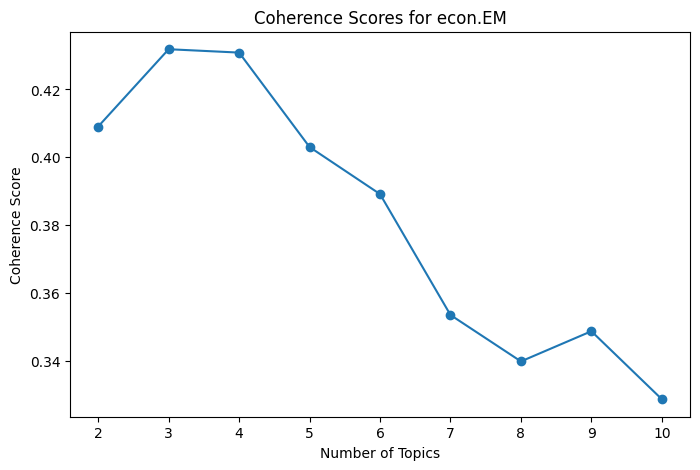

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(results_df["num_topics"], results_df["coherence"], marker="o")
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.title(f"Coherence Scores for {selected_category}")
plt.xticks(results_df["num_topics"])
plt.show()

## Select the Best LDA Model

The model with the highest coherence score is selected as the best candidate. However, coherence alone is not sufficient, so manual inspection of topic meaning is also necessary.

In [24]:
best_result = max(results, key=lambda x: x["coherence"])
best_lda_model = best_result["model"]

print("Best number of topics:", best_result["num_topics"])
print("Best coherence:", round(best_result["coherence"], 4))

Best number of topics: 3
Best coherence: 0.4318


## Inspect Learned Topics

The top words for each topic are printed to evaluate whether the topics are meaningful, interpretable, and distinct from one another.

In [25]:
for topic_id, topic_words in best_lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.020*"estimator" + 0.012*"estimation" + 0.012*"test" + 0.011*"inference" + 0.006*"regression" + 0.006*"function" + 0.006*"parameter" + 0.006*"distribution" + 0.006*"simulation" + 0.005*"application"

Topic 1: 0.008*"dynamic" + 0.006*"market" + 0.006*"forecast" + 0.006*"forecasting" + 0.006*"price" + 0.006*"economic" + 0.005*"risk" + 0.005*"network" + 0.005*"factor" + 0.005*"across"

Topic 2: 0.019*"effect" + 0.013*"outcome" + 0.012*"treatment" + 0.012*"treatment_effect" + 0.009*"design" + 0.009*"policy" + 0.009*"estimate" + 0.008*"assumption" + 0.007*"setting" + 0.006*"identification"



In [34]:
# re run model with doc_trigram to compare 

selected_category = "econ.EM"   # change this as needed

tri_lda_docs = docs_trigram

tri_dictionary = Dictionary(tri_lda_docs)
tri_dictionary.filter_extremes(no_below=5, no_above=0.5)

tri_corpus = [tri_dictionary.doc2bow(doc) for doc in tri_lda_docs]

refined_lda_model = LdaModel(
    corpus=tri_corpus,
    id2word=tri_dictionary,
    num_topics=3,
    random_state=42,
    chunksize=100,
    passes=10,
    alpha="auto",
    per_word_topics=True
)

for topic_id, topic_words in refined_lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.011*"outcome" + 0.009*"treatment" + 0.009*"effect" + 0.009*"treatment_effect" + 0.008*"estimate" + 0.008*"assumption" + 0.007*"identification" + 0.007*"setting" + 0.007*"policy" + 0.006*"design"

Topic 1: 0.008*"dynamic" + 0.006*"effect" + 0.006*"forecast" + 0.006*"price" + 0.006*"market" + 0.006*"forecasting" + 0.005*"economic" + 0.005*"across" + 0.004*"risk" + 0.004*"information"

Topic 2: 0.007*"parameter" + 0.007*"regression" + 0.007*"function" + 0.007*"distribution" + 0.006*"panel" + 0.006*"factor" + 0.005*"procedure" + 0.005*"propose" + 0.005*"linear" + 0.005*"simulation"



Although trigram modelling captures more granular domain-specific phrases, it introduces sparsity that weakens topic coherence and separability. Empirically, the bigram-based LDA produced more stable and interpretable topics, with clearer thematic distinctions. Hence, bigrams were adopted as the final representation, as they offer an optimal trade-off between expressiveness and model reliability.

## Assign a Dominant Topic to Each Document

To better understand the model output, each document is assigned its most probable topic. This allows us to inspect topic distribution and review example abstracts belonging to each topic.

In [28]:
def get_dominant_topic(lda_model, corpus):
    dominant_topics = []

    for bow in corpus:
        topic_probs = lda_model.get_document_topics(bow)
        dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
        dominant_topics.append(dominant_topic)

    return dominant_topics

cat_df = cat_df.reset_index(drop=True)
cat_df["dominant_topic"] = get_dominant_topic(best_lda_model, corpus)

cat_df[["abstract", "dominant_topic"]].head()

,abstract,dominant_topic
0,"In this paper, we survey recent econometric co...",1
1,This paper studies inference in randomized con...,2
2,The Neyman Allocation is used in many papers o...,0
3,Vector autogressions (VARs) are widely applied...,0
4,We propose a method to debias estimators based...,0


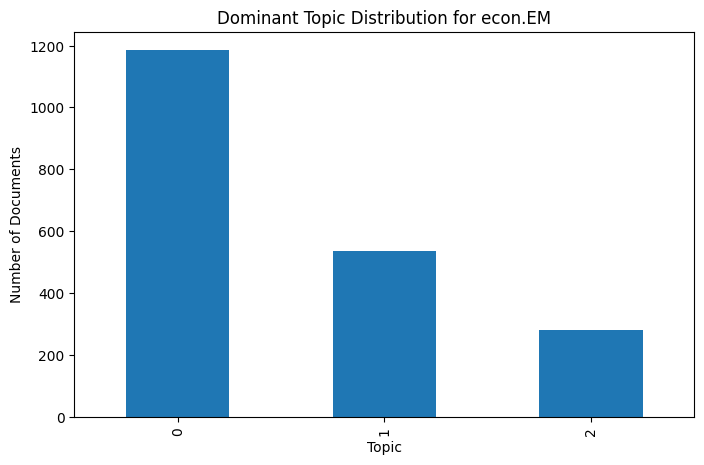

In [29]:
topic_dist = cat_df["dominant_topic"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
topic_dist.plot(kind="bar")
plt.xlabel("Topic")
plt.ylabel("Number of Documents")
plt.title(f"Dominant Topic Distribution for {selected_category}")
plt.show()

## Inspect Sample Documents for Each Topic

Topic keywords alone may not fully capture the meaning of each topic. Therefore, sample abstracts are reviewed for each dominant topic to validate whether the grouping is coherent and interpretable.

In [30]:
for topic_id in sorted(cat_df["dominant_topic"].unique()):
    print("=" * 80)
    print(f"TOPIC {topic_id}")
    print("=" * 80)

    topic_samples = cat_df[cat_df["dominant_topic"] == topic_id]["abstract"].head(3).tolist()

    for i, sample in enumerate(topic_samples, 1):
        print(f"\nSample {i}:")
        print(sample[:700])
        print()

TOPIC 0

Sample 1:
The Neyman Allocation is used in many papers on experimental design, which typically assume that researchers have access to large pilot studies. This may be unrealistic. To understand the properties of the Neyman Allocation with small pilots, we study its behavior in an asymptotic framework that takes pilot size to be fixed even as the size of the main wave tends to infinity. Our analysis shows that the Neyman Allocation can lead to estimates of the ATE with higher asymptotic variance than with (non-adaptive) balanced randomization. In particular, this happens when the outcome variable is relatively homoskedastic with respect to treatment status or when it exhibits high kurtosis. We provide 


Sample 2:
Vector autogressions (VARs) are widely applied when it comes to modeling and forecasting macroeconomic variables. In high dimensions, however, they are prone to overfitting. Bayesian methods, more concretely shrinkage priors, have shown to be successful in improving p

### Qualitative Evaluation of Topics

Manual inspection of representative documents per topic demonstrates strong intra-topic coherence and inter-topic distinction. Topic 0 is dominated by methodological econometric research, including estimation theory and statistical inference. Topic 1 captures applied and interdisciplinary work, linking economic phenomena such as climate change and financial systems with advanced computational techniques. Topic 2 clearly represents causal inference and experimental design, with a focus on randomized trials and treatment effect estimation.

These findings indicate that the bigram-based LDA model produces semantically meaningful and well-separated topics, aligning closely with known subfields in econometrics.

### Limitations of LDA Observed

One limitation observed is the presence of relatively broad topics, such as Topic 1, which combines applied economic domains (e.g., climate and finance) with machine learning-based methods. This can be attributed to LDA’s bag-of-words assumption, which ignores contextual and semantic relationships between words. As a result, documents from different subfields that share common vocabulary may be grouped into the same topic.

Additionally, the need to predefine the number of topics forces LDA to compress diverse themes into a limited set of topics, reducing granularity. This explains why applied and interdisciplinary research areas are not fully separated in the model output.

## Compare Unigram, Bigram, and Trigram Representations

To justify the phrase modelling choice, we compare coherence scores across unigram-only, bigram-enhanced, and trigram-enhanced representations.

This helps determine whether trigrams provide real improvement or merely increase sparsity.

In [31]:
def evaluate_representation(docs, num_topics):
    dictionary = Dictionary(docs)
    dictionary.filter_extremes(no_below=5, no_above=0.5)
    corpus = [dictionary.doc2bow(doc) for doc in docs]

    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        chunksize=100,
        passes=10,
        alpha="auto"
    )

    coherence_model = CoherenceModel(
        model=lda_model,
        texts=docs,
        dictionary=dictionary,
        coherence="c_v"
    )

    return coherence_model.get_coherence()


comparison = pd.DataFrame({
    "representation": ["unigram", "bigram", "trigram"],
    "coherence": [
        evaluate_representation(cat_docs, best_result["num_topics"]),
        evaluate_representation(docs_bigram, best_result["num_topics"]),
        evaluate_representation(docs_trigram, best_result["num_topics"])
    ]
})

comparison

,representation,coherence
0,unigram,0.41079
1,bigram,0.44308
2,trigram,0.40657


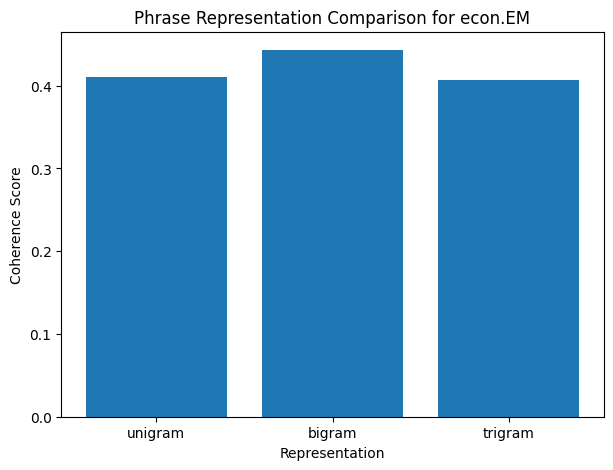

In [32]:
plt.figure(figsize=(7, 5))
plt.bar(comparison["representation"], comparison["coherence"])
plt.xlabel("Representation")
plt.ylabel("Coherence Score")
plt.title(f"Phrase Representation Comparison for {selected_category}")
plt.show()

In [37]:
import sys
!{sys.executable} -m pip install pyLDAvis

   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.6 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.6 MB 398.1 kB/s eta 0:00:06
   ------------ --------------------------- 0.8/2.6 MB 522.3 kB/s eta 0:00:04
   ---------------- ----------------------- 1.0/2.6 MB 681.3 kB/s eta 0:00:03
   -------------------- ------------------- 1.3/2.6 MB 769.2 kB/s eta 0:00:02
   ---------------------------- ----------- 1.8/2.6 MB 993.6 kB/s eta 0:00:01
   ------------------------------------ --- 2.4/2.6 MB 1.2

In [42]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from gensim.models.phrases import Phrases, Phraser

def run_lda_group(df, group_col, topic_range=None):

    if topic_range is None:
        if group_col == "broad_subject":
            topic_range = range(2, 16)   # max 15
        elif group_col == "primary_category":
            topic_range = range(2, 6)    # max 5
        else:
            topic_range = range(2, 9)    # fallback

    results = []

    for group in df[group_col].unique():

        group_df = df[df[group_col] == group]
        docs = group_df["tokens_clean"].tolist()

        if len(docs) < 20:
            continue

        # bigram
        bigram = Phraser(Phrases(docs, min_count=5, threshold=10))
        docs = [bigram[d] for d in docs]

        dictionary = Dictionary(docs)
        dictionary.filter_extremes(no_below=5, no_above=0.5)
        corpus = [dictionary.doc2bow(d) for d in docs]

        coherence_scores = []
        models = []

        for k in topic_range:
            model = LdaModel(
                corpus=corpus,
                id2word=dictionary,
                num_topics=k,
                random_state=42,
                passes=10
            )

            cm = CoherenceModel(
                model=model,
                texts=docs,
                dictionary=dictionary,
                coherence="c_v"
            )

            score = cm.get_coherence()

            coherence_scores.append(score)
            models.append(model)

        best_idx = coherence_scores.index(max(coherence_scores))
        best_k = list(topic_range)[best_idx]
        best_model = models[best_idx]

        print(f"\n=== {group} ===")
        for k, s in zip(topic_range, coherence_scores):
            print(f"k={k} → {s:.4f}")

        print(f"BEST k={best_k}")

        for t_id, words in best_model.print_topics(num_words=10):
            print(f"Topic {t_id}: {words}")

        results.append({
            "group": group,
            "best_k": best_k,
            "best_coherence": max(coherence_scores)
        })

    return pd.DataFrame(results)

In [43]:
broad_results = run_lda_group(df, "broad_subject")


=== biology ===
k=2 → 0.3475
k=3 → 0.4264
k=4 → 0.4405
k=5 → 0.4279
k=6 → 0.4370
k=7 → 0.4587
k=8 → 0.4689
k=9 → 0.5026
k=10 → 0.4751
k=11 → 0.4719
k=12 → 0.4743
k=13 → 0.4946
k=14 → 0.4878
k=15 → 0.4652
BEST k=9
Topic 0: 0.013*"prediction" + 0.012*"representation" + 0.011*"task" + 0.009*"graph" + 0.008*"learning" + 0.008*"feature" + 0.008*"network" + 0.008*"llm" + 0.007*"datasets" + 0.007*"information"
Topic 1: 0.012*"gene" + 0.009*"disease" + 0.008*"patient" + 0.007*"cancer" + 0.006*"associated" + 0.005*"clinical" + 0.005*"effect" + 0.005*"identified" + 0.005*"network" + 0.004*"individual"
Topic 2: 0.016*"brain" + 0.007*"neural" + 0.007*"human" + 0.006*"task" + 0.006*"representation" + 0.006*"visual" + 0.005*"feature" + 0.005*"across" + 0.004*"eeg" + 0.004*"image"
Topic 3: 0.008*"mechanism" + 0.008*"dynamic" + 0.007*"theory" + 0.006*"consciousness" + 0.005*"function" + 0.005*"interaction" + 0.005*"computational" + 0.005*"behavior" + 0.005*"process" + 0.004*"state"
Topic 4: 0.016*"ge

In [44]:
primary_results = run_lda_group(df, "primary_category")


=== q-bio.GN ===
k=2 → 0.2367
k=3 → 0.2561
k=4 → 0.2980
k=5 → 0.3165
BEST k=5
Topic 0: 0.014*"cancer" + 0.008*"gene" + 0.006*"algorithm" + 0.006*"rna-seq" + 0.005*"tumor" + 0.005*"cell" + 0.004*"patient" + 0.004*"transcript" + 0.004*"sample" + 0.004*"tool"
Topic 1: 0.014*"sequence" + 0.011*"read" + 0.007*"dna" + 0.007*"genomic" + 0.006*"genome" + 0.005*"algorithm" + 0.004*"gene" + 0.004*"dna_sequence" + 0.004*"clustering" + 0.003*"task"
Topic 2: 0.009*"tool" + 0.009*"genomic" + 0.008*"sequencing" + 0.006*"sequence" + 0.006*"variant" + 0.005*"sample" + 0.005*"genome" + 0.005*"datasets" + 0.004*"however" + 0.004*"application"
Topic 3: 0.021*"genome" + 0.015*"sequence" + 0.011*"gene" + 0.007*"protein" + 0.007*"dna" + 0.006*"evolution" + 0.005*"assembly" + 0.005*"genomic" + 0.005*"specie" + 0.004*"chromosome"
Topic 4: 0.029*"gene" + 0.007*"network" + 0.007*"disease" + 0.006*"gene_expression" + 0.006*"prediction" + 0.005*"protein" + 0.005*"sequence" + 0.004*"cell" + 0.004*"function" + 0.00

# Topic Modelling for all categories

In [ ]:
import pandas as pd
from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.phrases import Phrases, Phraser

all_topic_results = []
all_doc_results = []

for category in df["primary_category"].unique():

    cat_df = df[df["primary_category"] == category].copy().reset_index(drop=True)
    cat_docs = cat_df["tokens_clean"].tolist()

    # bigram
    bigram_model = Phraser(Phrases(cat_docs, min_count=5, threshold=10))
    docs_bigram = [bigram_model[doc] for doc in cat_docs]

    # LDA inputs
    dictionary = Dictionary(docs_bigram)
    dictionary.filter_extremes(no_below=5, no_above=0.5)
    corpus = [dictionary.doc2bow(doc) for doc in docs_bigram]

    # LDA model
    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=3,   # replace if tuning per category
        passes=10,
        random_state=42
    )

    # save topic words
    for topic_id, topic_words in lda_model.print_topics(num_words=10):
        all_topic_results.append({
            "category": category,
            "topic_id": topic_id,
            "topic_words": topic_words
        })

    # save dominant topic per document
    for i, bow in enumerate(corpus):
        topic_probs = lda_model.get_document_topics(bow)
        dominant_topic, dominant_prob = max(topic_probs, key=lambda x: x[1])

        all_doc_results.append({
            "category": category,
            "doc_index_within_category": i,
            "dominant_topic": dominant_topic,
            "dominant_topic_prob": dominant_prob,
            "title": cat_df.loc[i, "title"] if "title" in cat_df.columns else None,
            "abstract": cat_df.loc[i, "abstract"] if "abstract" in cat_df.columns else None
        })

# save outputs
topics_df = pd.DataFrame(all_topic_results)
docs_df = pd.DataFrame(all_doc_results)

topics_df.to_csv("lda_all_topics.csv", index=False)
docs_df.to_csv("lda_all_doc_topics.csv", index=False)